# Thực nghiệm Diffusion Maps trên Swiss Roll và MNIST

Notebook triển khai Diffusion Maps sau đó so sánh biểu diễn hai chiều với PCA và t-SNE. Sai số khoảng cách được tính bằng MRE theo Công thức ở Metric của bài báo *Deep Diffusion Maps*.

| Bước | Nội dung |
|---:|---|
| 1 | Khai báo thư viện và cấu hình |
| 2 | Chuẩn bị Swiss Roll và MNIST |
| 3 | Trực quan hóa dữ liệu ban đầu |
| 4 | Cài đặt Diffusion Maps |
| 5 | Cài đặt PCA và t-SNE |
| 6 | Cài đặt MRE theo Công thức (40) |
| 7 | Cài đặt MRE theo decile khoảng cách |
| 8 | Thực nghiệm Swiss Roll |
| 9 | Thực nghiệm MNIST |
| 10 | Tổng hợp và phân tích kết quả |

## Bước 1. Khai báo thư viện và cấu hình

Mọi phép lấy mẫu ngẫu nhiên sử dụng cùng SEED = 123, tương ứng cấu hình trong repository. Các hình được lưu dưới dạng PDF để sử dụng trong báo cáo.

In [ ]:
# Libraries and configuration
import os
import time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display
from scipy.linalg import eigh
from scipy.spatial.distance import pdist
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import mnist

SEED = 123
np.random.seed(SEED)

OUTPUT_DIR = '/content/pictures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_SWISS = 2000
N_MNIST = 5000
MNIST_CLASSES = 10
QUANTILE = 5.0e-3
TSNE_PERPLEXITY = 30
TSNE_ITERATIONS = 1000
BOOTSTRAP_REPLICATES = 1000
CONFIDENCE_LEVEL = 0.95
SPECTRUM_COMPONENTS = 50

CB = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442', 'blue': '#0072B2', 'vermilion': '#D55E00', 'pink': '#CC79A7', 'black': '#000000'}
METHOD_COLORS = {'Diffusion Maps': CB['blue'], 'PCA': CB['vermilion'], 't-SNE': CB['green']}
METHOD_ORDER = ['Diffusion Maps', 'PCA', 't-SNE']

mpl.rcParams.update({'font.family': 'serif', 'font.size': 8.2, 'axes.titlesize': 8.8, 'axes.labelsize': 8.2, 'xtick.labelsize': 7.0, 'ytick.labelsize': 7.0, 'legend.fontsize': 7.0, 'figure.dpi': 140, 'savefig.dpi': 300, 'axes.linewidth': 0.7, 'axes.spines.top': False, 'axes.spines.right': False, 'xtick.direction': 'out', 'ytick.direction': 'out', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'text.usetex': False})

print('Configuration ready.')

## Bước 2. Chuẩn bị Swiss Roll và MNIST

- **Swiss Roll:** 2.000 điểm, không thêm nhiễu; $D_a/D_b=1000/1000$.
- **MNIST:** 5.000 ảnh thuộc đầy đủ các chữ số từ 0 đến 9, lấy cân bằng 500 ảnh mỗi lớp và chuẩn hóa giá trị điểm ảnh về $[0,1]$.

Không chuẩn hóa z-score vì mã nguồn gốc sử dụng trực tiếp tọa độ Swiss Roll và ảnh MNIST đã chia cho 255.

Notebook giữ quy mô và phép chia $D_a/D_b=4000/1000$ của thí nghiệm MNIST trong bài báo, nhưng thay mẫu sáu chữ số 0–5 bằng tập 10 chữ số cân bằng theo đúng dữ liệu của nghiên cứu này. Ba phương pháp nhận cùng dữ liệu; MRE được báo cáo riêng trên cả $D_a$ và $D_b$, còn đồ thị MRE theo decile sử dụng $D_b$. Màu Swiss Roll mã hóa đồng thời hai tọa độ nội tại $(t,h)$ như mã nguồn gốc.

PCA và t-SNE chuẩn không cung cấp phép biến đổi ngoài mẫu theo quy trình của paper. Vì vậy, trong notebook này cả ba phương pháp được khớp trên toàn bộ $D_a\cup D_b$; ký hiệu $D_a,D_b$ chỉ xác định hai tập con dùng để báo cáo MRE, không được diễn giải như một thí nghiệm out-of-sample.

In [92]:
# Dataset preparation
X_swiss, t_swiss = make_swiss_roll(n_samples=N_SWISS, noise=0.0, random_state=SEED)
h_swiss = X_swiss[:, 1].copy()

def normalize_01(values):
    values = np.asarray(values, dtype=np.float64)
    span = np.ptp(values)
    return np.zeros_like(values) if span <= np.finfo(np.float64).eps else (values - values.min()) / span

def colormap_2d(x_values, y_values):
    x_values = normalize_01(x_values)[:, None]
    y_values = normalize_01(y_values)[:, None]
    bottom_left = np.array([0.5, 0.0, 0.5])
    bottom_right = np.array([0.0, 0.5, 0.5])
    top_left = np.array([1.0, 0.0, 1.0])
    top_right = np.array([0.0, 1.0, 1.0])
    bottom = bottom_left * (1.0 - x_values) + bottom_right * x_values
    top = top_left * (1.0 - x_values) + top_right * x_values
    return bottom * (1.0 - y_values) + top * y_values

swiss_colors = colormap_2d(t_swiss, h_swiss)

(X_train_all, y_train_all), (X_test_all, y_test_all) = mnist.load_data()
X_mnist_all = np.concatenate([X_train_all, X_test_all], axis=0)
y_mnist_all = np.concatenate([y_train_all, y_test_all], axis=0)
selection_rng = np.random.RandomState(SEED)
if N_MNIST % MNIST_CLASSES != 0: raise ValueError('N_MNIST must be divisible by MNIST_CLASSES for balanced sampling.')
samples_per_digit = N_MNIST // MNIST_CLASSES
selected_by_digit = []
for digit in range(MNIST_CLASSES):
    digit_indices = np.flatnonzero(y_mnist_all == digit)
    selection_rng.shuffle(digit_indices)
    selected_by_digit.append(digit_indices[:samples_per_digit])
selected = np.concatenate(selected_by_digit)
selection_rng.shuffle(selected)
X_mnist_images = X_mnist_all[selected]
y_mnist = y_mnist_all[selected].astype(int)
X_mnist = X_mnist_images.reshape(N_MNIST, -1).astype(np.float64) / 255.0

SWISS_TRAIN_INDEX, SWISS_TEST_INDEX = train_test_split(np.arange(N_SWISS), test_size=1000, random_state=SEED)
MNIST_TRAIN_INDEX, MNIST_TEST_INDEX = train_test_split(np.arange(N_MNIST), test_size=1000, random_state=SEED, stratify=y_mnist)
dataset_summary = pd.DataFrame([{'Dataset': 'Swiss Roll', 'Total': X_swiss.shape[0], 'D_a': len(SWISS_TRAIN_INDEX), 'D_b': len(SWISS_TEST_INDEX), 'Input dimension': X_swiss.shape[1], 'Classes': 'Not applicable'}, {'Dataset': 'MNIST (digits 0-9)', 'Total': X_mnist.shape[0], 'D_a': len(MNIST_TRAIN_INDEX), 'D_b': len(MNIST_TEST_INDEX), 'Input dimension': X_mnist.shape[1], 'Classes': MNIST_CLASSES}])
display(dataset_summary)
print('MNIST class counts:', np.bincount(y_mnist, minlength=MNIST_CLASSES).tolist())

,Dataset,Total,D_a,D_b,Input dimension,Classes
0,Swiss Roll,2000,1000,1000,3,Not applicable
1,MNIST (digits 0-9),5000,4000,1000,784,10


MNIST class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


## Bước 3. Trực quan hóa dữ liệu ban đầu

Hai hình đầu biểu diễn Swiss Roll trong không gian quan sát và trong tọa độ nội tại $(t,h)$. Hình thứ ba trình bày một ảnh đại diện cho mỗi chữ số MNIST được sử dụng trong thực nghiệm.

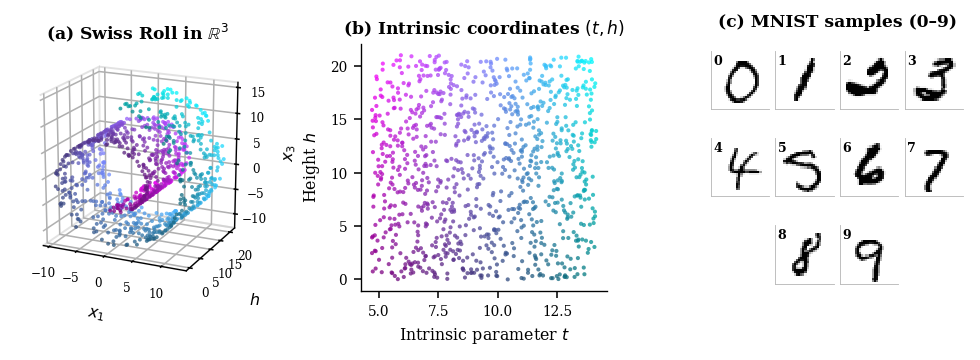

Saved: /content/pictures/datasets.pdf


In [93]:
# Initial data visualization
digit_examples = [X_mnist_images[MNIST_TRAIN_INDEX[np.flatnonzero(y_mnist[MNIST_TRAIN_INDEX] == digit)[0]]] for digit in range(MNIST_CLASSES)]
digit_positions = [(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3), (2, 1), (2, 2)]
fig = plt.figure(figsize=(7.2, 2.60))
grid = fig.add_gridspec(1, 3, left=0.04, right=0.985, bottom=0.16, top=0.88, wspace=0.40, width_ratios=[1.0, 1.0, 1.05])

ax1 = fig.add_subplot(grid[0, 0], projection='3d')
ax1.scatter(X_swiss[SWISS_TRAIN_INDEX, 0], X_swiss[SWISS_TRAIN_INDEX, 1], X_swiss[SWISS_TRAIN_INDEX, 2], c=swiss_colors[SWISS_TRAIN_INDEX], s=4, alpha=0.76, linewidths=0, depthshade=False, rasterized=True)
for pane in [ax1.xaxis.pane, ax1.yaxis.pane, ax1.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor('0.78')
ax1.set_xlabel(r'$x_1$', labelpad=-2)
ax1.set_ylabel(r'$h$', labelpad=-1)
ax1.set_zlabel(r'$x_3$', labelpad=-2)
ax1.tick_params(labelsize=6.2, pad=-1)
ax1.set_box_aspect((1.0, 0.82, 1.0))
ax1.view_init(elev=18, azim=-65)
ax1.set_title(r'(a) Swiss Roll in $\mathbb{R}^3$', fontweight='bold', pad=2)

ax2 = fig.add_subplot(grid[0, 1])
ax2.scatter(t_swiss[SWISS_TRAIN_INDEX], h_swiss[SWISS_TRAIN_INDEX], c=swiss_colors[SWISS_TRAIN_INDEX], s=4.5, alpha=0.76, linewidths=0, rasterized=True)
ax2.set_xlabel(r'Intrinsic parameter $t$')
ax2.set_ylabel(r'Height $h$')
ax2.set_title(r'(b) Intrinsic coordinates $(t,h)$', fontweight='bold', pad=5)
ax2.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.yaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.set_box_aspect(1.0)

ax3 = fig.add_subplot(grid[0, 2])
for digit, image in enumerate(digit_examples):
    row, column = digit_positions[digit]
    inset = ax3.inset_axes([column / 4 + 0.012, 1 - (row + 1) / 3 + 0.025, 0.225, 0.285])
    inset.imshow(image, cmap='gray_r', vmin=0, vmax=255, interpolation='nearest')
    inset.text(0.04, 0.94, str(digit), transform=inset.transAxes, ha='left', va='top', fontsize=6.5, fontweight='bold')
    inset.set_xticks([])
    inset.set_yticks([])
    for spine in inset.spines.values(): spine.set_color('0.72'); spine.set_linewidth(0.45)
ax3.set_title('(c) MNIST samples (0–9)', fontweight='bold', pad=5)
ax3.set_axis_off()

dataset_figure_path = os.path.join(OUTPUT_DIR, 'datasets.pdf')
fig.savefig(dataset_figure_path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
plt.show()
print('Saved:', dataset_figure_path)

## Bước 4. Cài đặt Diffusion Maps

Phần cài đặt dưới đây bám theo lớp DiffusionMaps trong repository:

$$
K_{ij}=\exp\left(-\frac{\lVert x_i-x_j\rVert^2}{2\sigma^2}\right),\qquad
W_{ij}=\frac{K_{ij}}{q_i^\alpha q_j^\alpha},\qquad q_i=\sum_jK_{ij}.
$$

Với $d_i=\sum_jW_{ij}$, ma trận đối xứng được phân rã là

$$
A=D^{-1/2}WD^{-1/2}.
$$

Biểu diễn $d$ chiều tại thời gian khuếch tán $t$ là

$$
\Psi^{(t)}(x_i)=\left(\lambda_2^t\psi_2(i),\ldots,\lambda_{d+1}^t\psi_{d+1}(i)\right).
$$

Băng thông $\sigma$ là phân vị $q=5\times10^{-3}$ của các khoảng cách Euclid cặp điểm. Tham số theo bài báo là $(\alpha,t)=(1,100)$ cho Swiss Roll và $(0,1)$ cho MNIST. MNIST được lấy hai thành phần để so sánh trực quan thống nhất với PCA và t-SNE; bài báo cũng thực hiện trường hợp $d=2$ để trực quan hóa.

In [94]:
# Diffusion Maps implementation
def estimate_sigma(X, quantile=5.0e-3):
    distances = pdist(np.asarray(X).reshape(len(X), -1), metric='euclidean')
    sigma = float(np.quantile(distances, quantile))
    if not np.isfinite(sigma) or sigma <= 0: raise ValueError('The selected sigma must be positive and finite.')
    return sigma

class DiffusionMaps:
    def __init__(self, n_components, sigma, steps=1, alpha=0.0):
        if n_components < 1: raise ValueError('n_components must be positive.')
        if sigma <= 0: raise ValueError('sigma must be positive.')
        if steps < 1: raise ValueError('steps must be positive.')
        self.n_components = int(n_components)
        self.sigma = float(sigma)
        self.steps = int(steps)
        self.alpha = float(alpha)

    @staticmethod
    def _fix_orientation(vectors):
        vectors = vectors.copy()
        for column in range(vectors.shape[1]):
            pivot = int(np.argmax(np.abs(vectors[:, column])))
            if vectors[pivot, column] < 0: vectors[:, column] *= -1
        return vectors

    def fit_transform(self, X, reference_index=None):
        X_flat = np.asarray(X, dtype=np.float64).reshape(len(X), -1)
        n_samples = X_flat.shape[0]
        if self.n_components >= n_samples: raise ValueError('n_components must be smaller than n_samples.')
        if reference_index is not None and not 0 <= reference_index < n_samples: raise ValueError('reference_index is outside the dataset.')

        affinity = pairwise_distances(X_flat, metric='sqeuclidean', n_jobs=-1)
        affinity *= -1.0 / (2.0 * self.sigma ** 2)
        np.exp(affinity, out=affinity)

        raw_degree = np.maximum(affinity.sum(axis=1), np.finfo(np.float64).tiny)
        density_scale = raw_degree ** self.alpha
        affinity /= density_scale[:, None]
        affinity /= density_scale[None, :]

        degree = np.maximum(affinity.sum(axis=1), np.finfo(np.float64).tiny)
        self.pi_ = degree / degree.sum()
        degree_sqrt = np.sqrt(degree)

        affinity /= degree[:, None]
        if reference_index is not None:
            transition_matrix = affinity if self.steps == 1 else np.linalg.matrix_power(affinity, self.steps)
            reference_row = transition_matrix[reference_index].copy()
            self.transition_probability_ = transition_matrix[:, reference_index].copy()
            inverse_pi = 1.0 / self.pi_
            distances = np.empty(n_samples, dtype=np.float64)
            for start in range(0, n_samples, 256):
                stop = min(start + 256, n_samples)
                delta = transition_matrix[start:stop] - reference_row
                distances[start:stop] = np.sqrt(np.einsum('ij,j,ij->i', delta, inverse_pi, delta, optimize=True))
            self.diffusion_distance_ = distances
            self.diffusion_distance_exact_ = True
            if self.steps > 1: del transition_matrix

        affinity *= degree_sqrt[:, None]
        affinity /= degree_sqrt[None, :]
        n_pairs = self.n_components + 1
        eigenvalues, eigenvectors = eigh(affinity, subset_by_index=[n_samples - n_pairs, n_samples - 1], driver='evr', check_finite=False, overwrite_a=True)
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = self._fix_orientation(eigenvectors[:, order])
        self.eigenvalues_ = eigenvalues
        self.eigenvectors_ = eigenvectors

        right_eigenvectors = eigenvectors / np.sqrt(self.pi_[:, None])
        selected_values = eigenvalues[1:self.n_components + 1]
        selected_vectors = right_eigenvectors[:, 1:self.n_components + 1]
        self.embedding_ = selected_vectors * selected_values[None, :] ** self.steps

        return self.embedding_

DM_PARAMETERS = {'Swiss Roll': {'quantile': QUANTILE, 'alpha': 1.0, 'steps': 100, 'n_components': 2}, 'MNIST': {'quantile': QUANTILE, 'alpha': 0.0, 'steps': 1, 'n_components': 2}}
display(pd.DataFrame(DM_PARAMETERS).T)

,quantile,alpha,steps,n_components
Swiss Roll,0.005,1.0,100.0,2.0
MNIST,0.005,0.0,1.0,2.0


## Bước 5. Cài đặt PCA và t-SNE

PCA và t-SNE nhận đúng cùng ma trận dữ liệu đã dùng cho Diffusion Maps. t-SNE sử dụng perplexity = 30, khởi tạo PCA và cùng seed để bảo đảm khả năng tái lập.

In [95]:
# PCA and t-SNE
def run_pca(X):
    return PCA(n_components=2, svd_solver='full').fit_transform(X)

def run_tsne(X, seed=SEED):
    common = {'n_components': 2, 'perplexity': TSNE_PERPLEXITY, 'init': 'pca', 'learning_rate': 'auto', 'random_state': seed}
    try: return TSNE(max_iter=TSNE_ITERATIONS, **common).fit_transform(X)
    except TypeError: return TSNE(n_iter=TSNE_ITERATIONS, **common).fit_transform(X)

def compute_embeddings(X, dataset_name, training_indices):
    parameters = DM_PARAMETERS[dataset_name]
    sigma = estimate_sigma(X[training_indices], parameters['quantile'])
    embeddings = {}
    runtimes = {}

    start = time.perf_counter()
    dm_model = DiffusionMaps(n_components=parameters['n_components'], sigma=sigma, steps=parameters['steps'], alpha=parameters['alpha'])
    embeddings['Diffusion Maps'] = dm_model.fit_transform(X)
    runtimes['Diffusion Maps'] = time.perf_counter() - start

    start = time.perf_counter()
    embeddings['PCA'] = run_pca(X)
    runtimes['PCA'] = time.perf_counter() - start

    start = time.perf_counter()
    embeddings['t-SNE'] = run_tsne(X)
    runtimes['t-SNE'] = time.perf_counter() - start
    return embeddings, runtimes, sigma

def fit_analysis_model(X, dataset_name, sigma, training_indices, reference_coordinate=None):
    parameters = DM_PARAMETERS[dataset_name]
    X_train = X[training_indices]
    local_reference = None if reference_coordinate is None else int(np.argmin(np.linalg.norm(X_train.reshape(len(X_train), -1) - np.asarray(reference_coordinate).reshape(1, -1), axis=1)))
    analysis_model = DiffusionMaps(n_components=min(SPECTRUM_COMPONENTS, len(X_train) - 2), sigma=sigma, steps=parameters['steps'], alpha=parameters['alpha'])
    analysis_model.fit_transform(X_train, reference_index=local_reference)
    return analysis_model, local_reference

## Bước 6. Cài đặt MRE theo Công thức bên dưới

Gọi $\widetilde{\gamma}_i$ là tọa độ tham chiếu do Diffusion Maps tạo ra và $\gamma_i$ là tọa độ của phương pháp cần đánh giá. Với $N$ điểm, sai số tương đối trung bình là

$$
\operatorname{MRE}=\frac{2}{N(N-1)}\sum_{i<j}
\frac{\left|\lVert\gamma_i-\gamma_j\rVert-\lVert\widetilde{\gamma}_i-\widetilde{\gamma}_j\rVert\right|}
{\lVert\widetilde{\gamma}_i-\widetilde{\gamma}_j\rVert}.
$$

Đúng theo bài báo, notebook không xoay, chuẩn hóa lại hoặc thay đổi tỷ lệ của các embedding trước khi tính MRE. Vì Diffusion Maps là biểu diễn tham chiếu nên MRE của chính phương pháp này bằng 0. MRE của PCA và t-SNE chỉ biểu thị mức độ khác biệt so với hình học khoảng cách của Diffusion Maps, không phải thước đo chất lượng tổng quát.

Khoảng tin cậy 95% của MRE được tính bằng bootstrap percentile với 1.000 lần lấy mẫu lại các sai số khoảng cách cặp trên tập $D_b$, tương ứng cách tổng hợp trong bài báo.

In [96]:
# MRE and percentile-bootstrap confidence interval
def pairwise_relative_errors(reference_embedding, candidate_embedding, indices=None):
    reference_embedding = np.asarray(reference_embedding, dtype=np.float64)
    candidate_embedding = np.asarray(candidate_embedding, dtype=np.float64)
    if reference_embedding.shape != candidate_embedding.shape: raise ValueError('Embeddings must have the same shape.')
    if indices is not None:
        reference_embedding = reference_embedding[indices]
        candidate_embedding = candidate_embedding[indices]
    reference_distances = pdist(reference_embedding, metric='euclidean')
    candidate_distances = pdist(candidate_embedding, metric='euclidean')
    valid = reference_distances > np.finfo(np.float64).eps
    relative_errors = np.abs(candidate_distances[valid] - reference_distances[valid]) / reference_distances[valid]
    return reference_distances[valid], relative_errors

def bootstrap_mean_ci(values, n_bootstrap=BOOTSTRAP_REPLICATES, confidence=CONFIDENCE_LEVEL, seed=SEED):
    values = np.asarray(values, dtype=np.float64)
    if np.all(values == values[0]): return float(values[0]), float(values[0])
    rng = np.random.default_rng(seed)
    bootstrap_means = np.empty(n_bootstrap, dtype=np.float64)
    for iteration in range(n_bootstrap):
        bootstrap_means[iteration] = np.mean(values[rng.integers(0, len(values), size=len(values))])
    tail = 100.0 * (1.0 - confidence) / 2.0
    return tuple(np.percentile(bootstrap_means, [tail, 100.0 - tail]))

def mre_statistics(reference_embedding, candidate_embedding, indices=None, seed=SEED):
    _, relative_errors = pairwise_relative_errors(reference_embedding, candidate_embedding, indices=indices)
    mean = float(np.mean(relative_errors))
    lower, upper = bootstrap_mean_ci(relative_errors, seed=seed)
    return {'MRE': mean, 'CI lower': lower, 'CI upper': upper, 'Pairs': len(relative_errors)}

## Bước 7. Cài đặt MRE theo decile khoảng cách

Các khoảng cách tham chiếu của Diffusion Maps trên $D_b$ được chia thành 10 nhóm có số cặp điểm gần bằng nhau. MRE được tính riêng trong từng nhóm để xác định sai số tập trung ở khoảng cách nhỏ, trung bình hay lớn.

In [97]:
# MRE by reference-distance decile
def mre_by_distance_decile(reference_embedding, candidate_embedding, dataset_name, method_name, indices):
    reference_distances, relative_errors = pairwise_relative_errors(reference_embedding, candidate_embedding, indices=indices)
    boundaries = np.quantile(reference_distances, np.linspace(0.0, 1.0, 11))
    records = []
    for decile in range(10):
        lower = boundaries[decile]
        upper = boundaries[decile + 1]
        mask = (reference_distances >= lower) & (reference_distances <= upper) if decile == 9 else (reference_distances >= lower) & (reference_distances < upper)
        records.append({'Dataset': dataset_name, 'Method': method_name, 'Decile': decile + 1, 'Lower distance': lower, 'Upper distance': upper, 'Pairs': int(mask.sum()), 'MRE': float(np.mean(relative_errors[mask]))})
    return pd.DataFrame(records)

def evaluate_embeddings(dataset_name, subset_name, embeddings, runtimes, evaluation_indices, include_deciles=False):
    reference = embeddings['Diffusion Maps']
    summary_rows = []
    decile_frames = []
    for method_index, method in enumerate(METHOD_ORDER):
        statistics = mre_statistics(reference, embeddings[method], indices=evaluation_indices, seed=SEED + method_index)
        summary_rows.append({'Dataset': dataset_name, 'Subset': subset_name, 'Method': method, 'Evaluation samples': len(evaluation_indices), **statistics, 'Runtime (s)': runtimes[method]})
        if include_deciles: decile_frames.append(mre_by_distance_decile(reference, embeddings[method], dataset_name, method, indices=evaluation_indices))
    decile_results = pd.concat(decile_frames, ignore_index=True) if decile_frames else pd.DataFrame()
    return pd.DataFrame(summary_rows), decile_results

def make_mre_report(summary):
    report = summary[['Dataset', 'Subset', 'Method', 'Evaluation samples', 'Pairs', 'MRE', 'CI lower', 'CI upper', 'Runtime (s)']].copy()
    report['MRE (%)'] = 100.0 * report['MRE']
    report['95% CI (%)'] = report.apply(lambda row: f'[{100.0 * row["CI lower"]:.2f}, {100.0 * row["CI upper"]:.2f}]', axis=1)
    return report[['Dataset', 'Subset', 'Method', 'Evaluation samples', 'Pairs', 'MRE (%)', '95% CI (%)', 'Runtime (s)']]

def plot_embedding_row(embeddings, colors, indices, dataset_name, output_name):
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45))
    for index, method in enumerate(METHOD_ORDER):
        coordinates = embeddings[method][indices]
        axes[index].scatter(coordinates[:, 0], coordinates[:, 1], c=colors[indices], s=5 if dataset_name == 'Swiss Roll' else 6, alpha=0.72, linewidths=0, rasterized=True)
        axes[index].set_title(f'({chr(97 + index)}) {method}', fontweight='bold', pad=5)
        axes[index].set_xlabel('Component 1')
        axes[index].set_ylabel('Component 2' if index == 0 else '')
        axes[index].xaxis.set_major_locator(ticker.MaxNLocator(4))
        axes[index].yaxis.set_major_locator(ticker.MaxNLocator(4))
        axes[index].set_box_aspect(1.0)
    if dataset_name == 'MNIST':
        legend_handles = [plt.Line2D([], [], linestyle='none', marker='o', markersize=4.0, markerfacecolor=plt.get_cmap('tab10')(digit), markeredgewidth=0, label=str(digit)) for digit in range(MNIST_CLASSES)]
        fig.legend(handles=legend_handles, title='Digit', ncol=10, loc='lower center', bbox_to_anchor=(0.5, 0.01), frameon=False, handletextpad=0.20, columnspacing=0.55)
        fig.subplots_adjust(left=0.07, right=0.985, bottom=0.29, top=0.88, wspace=0.34)
    else:
        fig.subplots_adjust(left=0.07, right=0.985, bottom=0.20, top=0.88, wspace=0.34)
    path = os.path.join(OUTPUT_DIR, output_name)
    fig.savefig(path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
    plt.show()
    print('Saved:', path)

def draw_swiss_diffusion_profile(fig, ax, values, title, colorbar_label):
    profile_colors = normalize_01(values)
    X_train = X_swiss[SWISS_TRAIN_INDEX]
    scatter = ax.scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c=profile_colors, cmap='viridis', vmin=0, vmax=1, s=4.5, alpha=0.80, linewidths=0, depthshade=False, rasterized=True)
    ax.scatter(*X_train[SWISS_REFERENCE_LOCAL], marker='*', s=68, c=CB['yellow'], edgecolors='black', linewidths=0.7, depthshade=False)
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]: pane.fill = False; pane.set_edgecolor('0.80')
    ax.set_xlabel(r'$x_1$', labelpad=-2)
    ax.set_ylabel(r'$h$', labelpad=-1)
    ax.set_zlabel(r'$x_3$', labelpad=-2)
    ax.tick_params(labelsize=6.2, pad=-1)
    ax.view_init(elev=18, azim=-65)
    ax.set_box_aspect((1.0, 0.82, 1.0))
    ax.set_title(title, fontweight='bold', pad=3)
    colorbar = fig.colorbar(scatter, ax=ax, shrink=0.58, pad=0.015, fraction=0.045, aspect=18)
    colorbar.set_label(colorbar_label, fontsize=7.2)
    colorbar.ax.tick_params(labelsize=6.2)

def log_gaussian_density(values, mean, variance):
    variance = max(float(variance), np.finfo(np.float64).tiny)
    return -0.5 * np.log(2.0 * np.pi * variance) - (values - mean) ** 2 / (2.0 * variance)

def likelihood_curve(spectral_values, max_dimension=25):
    spectral_values = np.asarray(spectral_values, dtype=np.float64)
    dimensions = np.arange(1, min(max_dimension, len(spectral_values) - 1) + 1)
    scores = np.empty(len(dimensions), dtype=np.float64)
    for position, dimension in enumerate(dimensions):
        retained = spectral_values[:dimension]
        discarded = spectral_values[dimension:]
        retained_variance = np.var(retained, ddof=1 if len(retained) > 1 else 0)
        discarded_variance = np.var(discarded, ddof=1 if len(discarded) > 1 else 0)
        pooled_denominator = max(len(retained) + len(discarded) - 2, 1)
        pooled_variance = ((len(retained) - 1) * retained_variance + (len(discarded) - 1) * discarded_variance) / pooled_denominator
        scores[position] = log_gaussian_density(retained, retained.mean(), pooled_variance).sum() + log_gaussian_density(discarded, discarded.mean(), pooled_variance).sum()
    return dimensions, scores

def draw_spectrum_likelihood(ax, model, title):
    spectral_values = model.eigenvalues_[1:] ** model.steps
    displayed = spectral_values[:25]
    component_axis = np.arange(1, len(displayed) + 1)
    dimensions, scores = likelihood_curve(spectral_values, max_dimension=25)
    eigen_line = ax.plot(component_axis, displayed, color=CB['blue'], marker='o', markersize=2.6, linewidth=1.0)[0]
    ax.set_xlabel('Component index')
    ax.set_ylabel('Scaled eigenvalue', color=CB['blue'])
    ax.tick_params(axis='y', colors=CB['blue'])
    ax.set_title(title, fontweight='bold', pad=5)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(6, integer=True))
    likelihood_axis = ax.twinx()
    likelihood_line = likelihood_axis.plot(dimensions, scores, color=CB['vermilion'], linestyle='--', linewidth=1.1)[0]
    likelihood_axis.set_ylabel('Log-likelihood', color=CB['vermilion'])
    likelihood_axis.tick_params(axis='y', colors=CB['vermilion'])
    ax.axvline(2, color='0.35', linewidth=0.75, linestyle=':')
    ax.legend([eigen_line, likelihood_line], ['Eigenvalue', 'Log-likelihood'], frameon=False, loc='best')

def draw_mre_deciles(ax, dataset_name, title, show_ylabel=True):
    subset = DECILE_RESULTS[(DECILE_RESULTS['Dataset'] == dataset_name) & (DECILE_RESULTS['Method'] != 'Diffusion Maps')]
    for method in ['PCA', 't-SNE']:
        curve = subset[subset['Method'] == method]
        ax.plot(curve['Decile'], 100.0 * curve['MRE'], marker='o', markersize=3.2, linewidth=1.05, color=METHOD_COLORS[method], label=method)
    ax.set_xlabel('Reference-distance decile')
    ax.set_ylabel('MRE (%)' if show_ylabel else '')
    ax.set_title(title, fontweight='bold', pad=5)
    ax.set_xticks(np.arange(1, 11))
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)
    ax.legend(frameon=False, loc='best')

## Bước 8. Thực nghiệm Swiss Roll

Diffusion Maps sử dụng $q=5\times10^{-3}$, $\alpha=1$ và $t=100$ như Bảng 1 của bài báo. Màu biểu diễn tham số nội tại $t$ của Swiss Roll.

Swiss Roll sigma = 1.691608, alpha = 1, diffusion time = 100
Leading eigenvalues on D_a: [1.         0.99685227 0.99308652 0.9866289  0.97934001 0.975428
 0.97343482 0.96924614]


,Dataset,Subset,Method,Evaluation samples,Pairs,MRE (%),95% CI (%),Runtime (s)
0,Swiss Roll,$D_a$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",2.456
1,Swiss Roll,$D_a$,PCA,1000,499500,1967.578,"[1954.79, 1980.75]",0.003
2,Swiss Roll,$D_a$,t-SNE,1000,499500,12166.572,"[11959.03, 12393.53]",13.209
3,Swiss Roll,$D_b$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",2.456
4,Swiss Roll,$D_b$,PCA,1000,499500,2076.494,"[2061.79, 2090.65]",0.003
5,Swiss Roll,$D_b$,t-SNE,1000,499500,13607.047,"[13353.52, 13858.07]",13.209


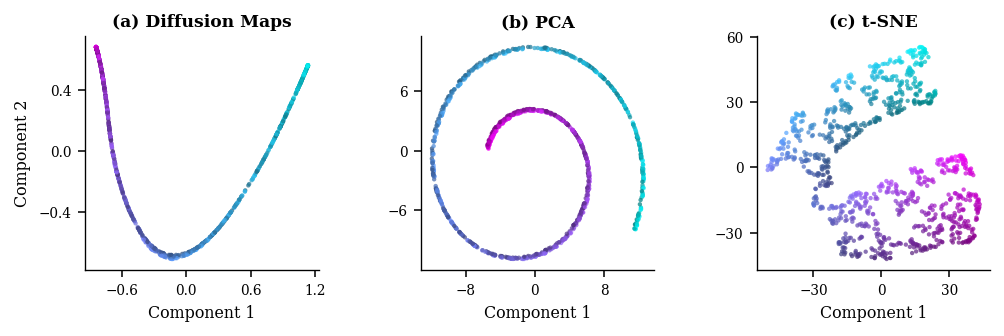

Saved: /content/pictures/swiss_embeddings.pdf


In [98]:
# Swiss Roll experiment
EMBEDDINGS_SWISS, RUNTIMES_SWISS, SIGMA_SWISS = compute_embeddings(X_swiss, 'Swiss Roll', SWISS_TRAIN_INDEX)
DM_SWISS_ANALYSIS, SWISS_REFERENCE_LOCAL = fit_analysis_model(X_swiss, 'Swiss Roll', SIGMA_SWISS, SWISS_TRAIN_INDEX, reference_coordinate=np.array([0.0, -1.0, -15.0]))
SWISS_SUMMARY_A, _ = evaluate_embeddings('Swiss Roll', r'$D_a$', EMBEDDINGS_SWISS, RUNTIMES_SWISS, SWISS_TRAIN_INDEX)
SWISS_SUMMARY_B, SWISS_DECILES = evaluate_embeddings('Swiss Roll', r'$D_b$', EMBEDDINGS_SWISS, RUNTIMES_SWISS, SWISS_TEST_INDEX, include_deciles=True)
SWISS_SUMMARY = pd.concat([SWISS_SUMMARY_A, SWISS_SUMMARY_B], ignore_index=True)

print(f'Swiss Roll sigma = {SIGMA_SWISS:.6f}, alpha = 1, diffusion time = 100')
print('Leading eigenvalues on D_a:', np.round(DM_SWISS_ANALYSIS.eigenvalues_[:8], 8))
display(make_mre_report(SWISS_SUMMARY).round({'MRE (%)': 3, 'Runtime (s)': 3}))
plot_embedding_row(EMBEDDINGS_SWISS, swiss_colors, SWISS_TEST_INDEX, 'Swiss Roll', 'swiss_embeddings.pdf')

## Bước 9. Thực nghiệm MNIST

Diffusion Maps sử dụng $q=5\times10^{-3}$, $\alpha=0$ và $t=1$. Nhãn chữ số chỉ được sử dụng để tô màu sau khi hoàn thành giảm chiều.

MNIST sigma = 5.714496, alpha = 0, diffusion time = 1
Leading eigenvalues on D_a: [1.         0.15670561 0.12641606 0.10133107 0.08940613 0.08651582
 0.07809434 0.06095013]


,Dataset,Subset,Method,Evaluation samples,Pairs,MRE (%),95% CI (%),Runtime (s)
0,MNIST,$D_a$,Diffusion Maps,4000,7998000,0.000,"[0.00, 0.00]",17.415
1,MNIST,$D_a$,PCA,4000,7998000,1403.752,"[1403.41, 1404.13]",0.822
2,MNIST,$D_a$,t-SNE,4000,7998000,31438.937,"[31400.30, 31478.41]",43.404
3,MNIST,$D_b$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",17.415
4,MNIST,$D_b$,PCA,1000,499500,1411.063,"[1409.81, 1412.33]",0.822
5,MNIST,$D_b$,t-SNE,1000,499500,32596.720,"[32444.88, 32762.74]",43.404


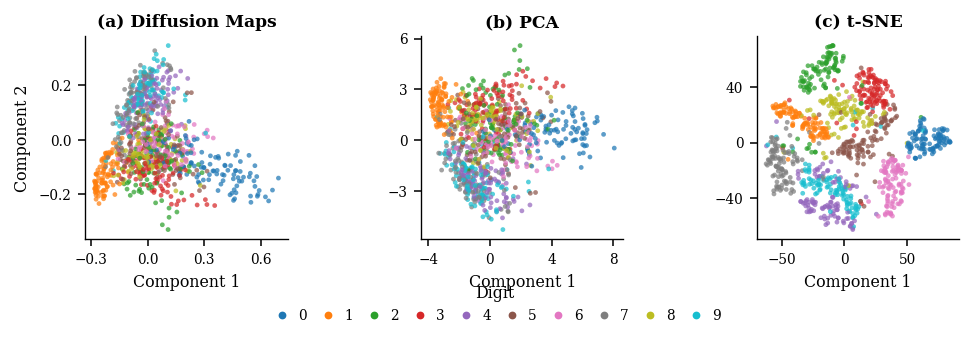

Saved: /content/pictures/mnist_embeddings.pdf


In [99]:
# MNIST experiment
EMBEDDINGS_MNIST, RUNTIMES_MNIST, SIGMA_MNIST = compute_embeddings(X_mnist, 'MNIST', MNIST_TRAIN_INDEX)
DM_MNIST_ANALYSIS, _ = fit_analysis_model(X_mnist, 'MNIST', SIGMA_MNIST, MNIST_TRAIN_INDEX)
MNIST_SUMMARY_A, _ = evaluate_embeddings('MNIST', r'$D_a$', EMBEDDINGS_MNIST, RUNTIMES_MNIST, MNIST_TRAIN_INDEX)
MNIST_SUMMARY_B, MNIST_DECILES = evaluate_embeddings('MNIST', r'$D_b$', EMBEDDINGS_MNIST, RUNTIMES_MNIST, MNIST_TEST_INDEX, include_deciles=True)
MNIST_SUMMARY = pd.concat([MNIST_SUMMARY_A, MNIST_SUMMARY_B], ignore_index=True)
mnist_colors = np.asarray([plt.get_cmap('tab10')(label) for label in y_mnist])

print(f'MNIST sigma = {SIGMA_MNIST:.6f}, alpha = 0, diffusion time = 1')
print('Leading eigenvalues on D_a:', np.round(DM_MNIST_ANALYSIS.eigenvalues_[:8], 8))
display(make_mre_report(MNIST_SUMMARY).round({'MRE (%)': 3, 'Runtime (s)': 3}))
plot_embedding_row(EMBEDDINGS_MNIST, mnist_colors, MNIST_TEST_INDEX, 'MNIST', 'mnist_embeddings.pdf')

## Bước 10. Tổng hợp và phân tích kết quả

Bước cuối tạo một hình tổng hợp theo lưới 4 hàng $\times$ 2 cột. Sáu panel đầu chiếm từng ô; panel cuối trải rộng cả hai cột ở hàng thứ tư:

- Phân bố xác suất chuyển tiếp và khoảng cách khuếch tán trên $D_a$ của Swiss Roll.
- Phổ trị riêng và đường log-likelihood trên $D_a$ của hai dữ liệu.
- Bảng tham số Diffusion Maps.
- Bảng MRE và khoảng tin cậy bootstrap 95%.
- Bảng và đồ thị MRE theo decile khoảng cách.
- Panel cuối là biểu đồ tổng hợp MRE trên $D_a$ và $D_b$.
- Các bảng tham số, MRE, decile và thời gian chạy được lưu riêng dưới dạng CSV.

Đối với Swiss Roll, ma trận chuyển tiếp $P^t$ được xây dựng trên tập $D_a$ với thời gian khuếch tán $t$ đã xác định. Từ một điểm tham chiếu $x_r$, phân bố chuyển tiếp được biểu diễn bởi các phần tử của $P^t$, còn khoảng cách khuếch tán $d_{\mathrm{dif}}^{(t)}(x_i,x_r)$ được tính từ sai khác có trọng số giữa hai hàng tương ứng của $P^t$. Hai đại lượng này cho phép kiểm tra trực tiếp liệu quá trình khuếch tán có phản ánh tính liên thông cục bộ của đa tạp Swiss Roll hay không.

Đường likelihood được xây dựng từ 50 trị riêng không tầm thường lớn nhất sau khi xét hệ số $\lambda_j^t$. Đây là xấp xỉ phổ phục vụ chẩn đoán số chiều trong giới hạn tài nguyên của Google Colab; xấp xỉ này không làm thay đổi biểu diễn hai chiều hoặc các giá trị MRE được báo cáo.

MRE trong thực nghiệm này là một chỉ số **đối chiếu theo tham chiếu**. Cụ thể, chỉ số đo sai khác tương đối giữa các khoảng cách cặp điểm của PCA hoặc t-SNE và các khoảng cách tương ứng trong biểu diễn Diffusion Maps. Vì vậy:

1. MRE nhỏ hơn cho thấy phương pháp tạo ra cấu trúc khoảng cách gần với Diffusion Maps hơn; kết quả này không đồng nghĩa với chất lượng giảm chiều tổng quát tốt hơn trên mọi tiêu chí.
2. MRE của Diffusion Maps bằng 0 là hệ quả trực tiếp của việc sử dụng chính biểu diễn này làm chuẩn, không phải bằng chứng thực nghiệm cho thấy Diffusion Maps vượt trội hơn PCA hoặc t-SNE.
3. Do sai số tương đối có thể tăng mạnh khi khoảng cách tham chiếu rất nhỏ, kết quả tổng hợp phải được xem cùng MRE theo decile, hình dạng embedding và thời gian tính toán trước khi đưa ra kết luận.

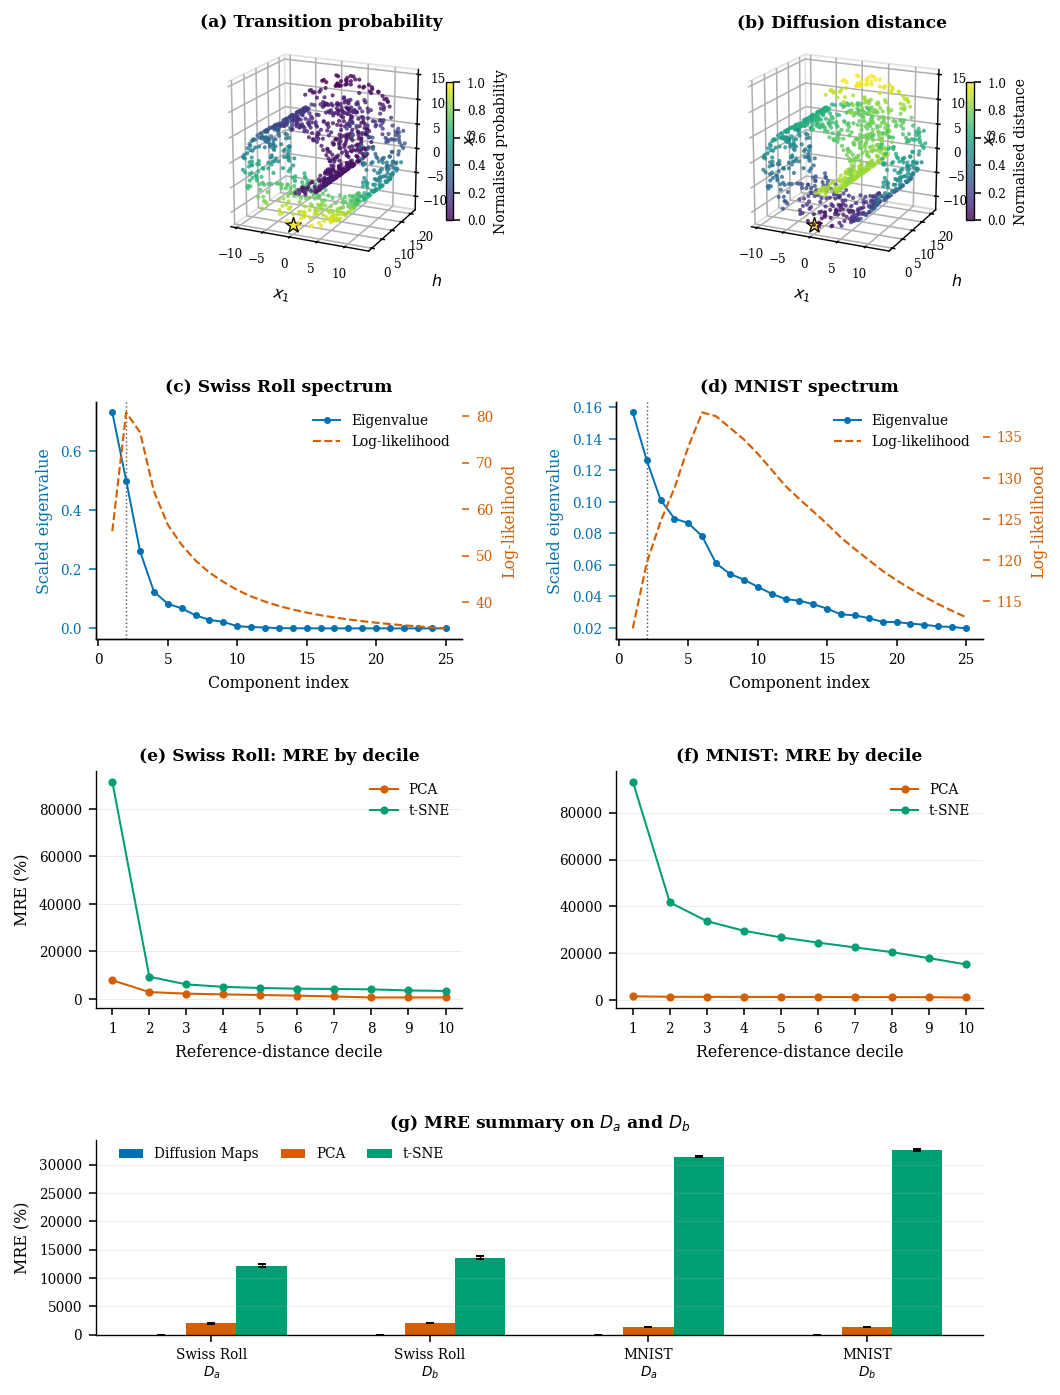

Diffusion Maps parameters


,Dataset,n,d used,q,sigma,alpha,t
0,Swiss Roll,2000,2,0.005,1.691608,1.0,100
1,MNIST (digits 0–9),5000,2,0.005,5.714496,0.0,1


MRE with 95% percentile-bootstrap confidence intervals


,Dataset,Subset,Method,Evaluation samples,Pairs,MRE (%),95% CI (%),Runtime (s)
0,Swiss Roll,$D_a$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",2.456
1,Swiss Roll,$D_a$,PCA,1000,499500,1967.578,"[1954.79, 1980.75]",0.003
2,Swiss Roll,$D_a$,t-SNE,1000,499500,12166.572,"[11959.03, 12393.53]",13.209
3,Swiss Roll,$D_b$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",2.456
4,Swiss Roll,$D_b$,PCA,1000,499500,2076.494,"[2061.79, 2090.65]",0.003
5,Swiss Roll,$D_b$,t-SNE,1000,499500,13607.047,"[13353.52, 13858.07]",13.209
6,MNIST,$D_a$,Diffusion Maps,4000,7998000,0.000,"[0.00, 0.00]",17.415
7,MNIST,$D_a$,PCA,4000,7998000,1403.752,"[1403.41, 1404.13]",0.822
8,MNIST,$D_a$,t-SNE,4000,7998000,31438.937,"[31400.30, 31478.41]",43.404
9,MNIST,$D_b$,Diffusion Maps,1000,499500,0.000,"[0.00, 0.00]",17.415


MRE by reference-distance decile (%)


Method,Dataset,Decile,Diffusion Maps,PCA,t-SNE
0,MNIST,1,0.0,1685.277,93233.249
1,MNIST,2,0.0,1476.000,41704.070
2,MNIST,3,0.0,1450.008,33722.754
3,MNIST,4,0.0,1433.459,29627.969
4,MNIST,5,0.0,1417.592,26807.620
5,MNIST,6,0.0,1401.754,24586.965
6,MNIST,7,0.0,1384.836,22529.477
7,MNIST,8,0.0,1359.008,20513.535
8,MNIST,9,0.0,1310.858,17952.130
9,MNIST,10,0.0,1191.834,15289.432


Runtime (s)


,Dataset,Method,Runtime (s)
0,Swiss Roll,Diffusion Maps,2.456
1,Swiss Roll,PCA,0.003
2,Swiss Roll,t-SNE,13.209
3,MNIST,Diffusion Maps,17.415
4,MNIST,PCA,0.822
5,MNIST,t-SNE,43.404


Swiss Roll $D_a$: PCA gần biểu diễn Diffusion Maps hơn t-SNE theo MRE (1967.58% so với 12166.57%).
Swiss Roll $D_b$: PCA gần biểu diễn Diffusion Maps hơn t-SNE theo MRE (2076.49% so với 13607.05%).
MNIST $D_a$: PCA gần biểu diễn Diffusion Maps hơn t-SNE theo MRE (1403.75% so với 31438.94%).
MNIST $D_b$: PCA gần biểu diễn Diffusion Maps hơn t-SNE theo MRE (1411.06% so với 32596.72%).
Swiss Roll, PCA: MRE decile 1 = 7844.86%; trung bình decile 2–10 = 1435.56%.
Swiss Roll, t-SNE: MRE decile 1 = 91478.77%; trung bình decile 2–10 = 4954.63%.
MNIST, PCA: MRE decile 1 = 1685.28%; trung bình decile 2–10 = 1380.59%.
MNIST, t-SNE: MRE decile 1 = 93233.25%; trung bình decile 2–10 = 25859.33%.
Saved: /content/pictures/results_overview.pdf
Saved: /content/pictures/mre_summary.csv
Saved: /content/pictures/mre_by_decile.csv
Saved: /content/pictures/diffusion_map_parameters.csv
Saved: /content/pictures/runtime_summary.csv


In [100]:
# Result aggregation and analysis
RESULTS = pd.concat([SWISS_SUMMARY, MNIST_SUMMARY], ignore_index=True)
DECILE_RESULTS = pd.concat([SWISS_DECILES, MNIST_DECILES], ignore_index=True)
MRE_REPORT = make_mre_report(RESULTS)
PARAMETER_RESULTS = pd.DataFrame([{'Dataset': 'Swiss Roll', 'n': N_SWISS, 'd used': 2, 'q': QUANTILE, 'sigma': SIGMA_SWISS, 'alpha': 1.0, 't': 100}, {'Dataset': 'MNIST (digits 0–9)', 'n': N_MNIST, 'd used': 2, 'q': QUANTILE, 'sigma': SIGMA_MNIST, 'alpha': 0.0, 't': 1}])
DECILE_TABLE = DECILE_RESULTS.assign(**{'MRE (%)': 100.0 * DECILE_RESULTS['MRE']}).pivot_table(index=['Dataset', 'Decile'], columns='Method', values='MRE (%)').reset_index()
RUNTIME_RESULTS = RESULTS[['Dataset', 'Method', 'Runtime (s)']].drop_duplicates().reset_index(drop=True)

# Combined 4 x 2 results figure; the final panel spans both columns
fig = plt.figure(figsize=(7.2, 10.0))
grid = fig.add_gridspec(4, 2, left=0.075, right=0.955, bottom=0.055, top=0.985, wspace=0.42, hspace=0.58, height_ratios=[1.0, 1.0, 1.0, 0.82])

ax_a = fig.add_subplot(grid[0, 0], projection='3d')
ax_b = fig.add_subplot(grid[0, 1], projection='3d')
draw_swiss_diffusion_profile(fig, ax_a, DM_SWISS_ANALYSIS.transition_probability_, '(a) Transition probability', 'Normalised probability')
draw_swiss_diffusion_profile(fig, ax_b, DM_SWISS_ANALYSIS.diffusion_distance_, '(b) Diffusion distance', 'Normalised distance')

ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])
draw_spectrum_likelihood(ax_c, DM_SWISS_ANALYSIS, '(c) Swiss Roll spectrum')
draw_spectrum_likelihood(ax_d, DM_MNIST_ANALYSIS, '(d) MNIST spectrum')

ax_e = fig.add_subplot(grid[2, 0])
ax_f = fig.add_subplot(grid[2, 1])
draw_mre_deciles(ax_e, 'Swiss Roll', '(e) Swiss Roll: MRE by decile')
draw_mre_deciles(ax_f, 'MNIST', '(f) MNIST: MRE by decile', show_ylabel=False)

ax_g = fig.add_subplot(grid[3, :])
groups = [('Swiss Roll', r'$D_a$'), ('Swiss Roll', r'$D_b$'), ('MNIST', r'$D_a$'), ('MNIST', r'$D_b$')]
x_positions = np.arange(len(groups))
bar_width = 0.23
for method_index, method in enumerate(METHOD_ORDER):
    method_rows = pd.concat([RESULTS[(RESULTS['Dataset'] == dataset_name) & (RESULTS['Subset'] == subset_name) & (RESULTS['Method'] == method)] for dataset_name, subset_name in groups], ignore_index=True)
    values = 100.0 * method_rows['MRE'].to_numpy()
    lower_error = 100.0 * np.maximum(0.0, (method_rows['MRE'] - method_rows['CI lower']).to_numpy())
    upper_error = 100.0 * np.maximum(0.0, (method_rows['CI upper'] - method_rows['MRE']).to_numpy())
    ax_g.bar(x_positions + (method_index - 1) * bar_width, values, width=bar_width, color=METHOD_COLORS[method], label=method, yerr=np.vstack([lower_error, upper_error]), capsize=2.2, error_kw={'linewidth': 0.7})
ax_g.set_xticks(x_positions)
ax_g.set_xticklabels(['Swiss Roll\n$D_a$', 'Swiss Roll\n$D_b$', 'MNIST\n$D_a$', 'MNIST\n$D_b$'])
ax_g.set_ylabel('MRE (%)')
ax_g.set_title('(g) MRE summary on $D_a$ and $D_b$', fontweight='bold', pad=6)
ax_g.legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0.02, 0.99), borderaxespad=0.0, handlelength=1.8, columnspacing=1.6)
ax_g.grid(axis='y', linewidth=0.35, alpha=0.35)

results_figure_path = os.path.join(OUTPUT_DIR, 'results_overview.pdf')
summary_path = os.path.join(OUTPUT_DIR, 'mre_summary.csv')
decile_path = os.path.join(OUTPUT_DIR, 'mre_by_decile.csv')
parameter_path = os.path.join(OUTPUT_DIR, 'diffusion_map_parameters.csv')
runtime_path = os.path.join(OUTPUT_DIR, 'runtime_summary.csv')
fig.savefig(results_figure_path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
RESULTS.to_csv(summary_path, index=False)
DECILE_RESULTS.to_csv(decile_path, index=False)
PARAMETER_RESULTS.to_csv(parameter_path, index=False)
RUNTIME_RESULTS.to_csv(runtime_path, index=False)
plt.show()

print('Diffusion Maps parameters')
display(PARAMETER_RESULTS.round({'q': 5, 'sigma': 6}))
print('MRE with 95% percentile-bootstrap confidence intervals')
display(MRE_REPORT.round({'MRE (%)': 3, 'Runtime (s)': 3}))
print('MRE by reference-distance decile (%)')
display(DECILE_TABLE.round(3))
print('Runtime (s)')
display(RUNTIME_RESULTS.round({'Runtime (s)': 3}))

for dataset_name in ['Swiss Roll', 'MNIST']:
    for subset_name in [r'$D_a$', r'$D_b$']:
        comparison = RESULTS[(RESULTS['Dataset'] == dataset_name) & (RESULTS['Subset'] == subset_name) & (RESULTS['Method'] != 'Diffusion Maps')].sort_values('MRE')
        best = comparison.iloc[0]
        other = comparison.iloc[1]
        print(f'{dataset_name} {subset_name}: {best["Method"]} gần biểu diễn Diffusion Maps hơn {other["Method"]} theo MRE ({100.0 * best["MRE"]:.2f}% so với {100.0 * other["MRE"]:.2f}%).')

for dataset_name in ['Swiss Roll', 'MNIST']:
    for method in ['PCA', 't-SNE']:
        curve = DECILE_RESULTS[(DECILE_RESULTS['Dataset'] == dataset_name) & (DECILE_RESULTS['Method'] == method)].sort_values('Decile')
        first_decile = 100.0 * curve.iloc[0]['MRE']
        remaining_deciles = 100.0 * curve.iloc[1:]['MRE'].mean()
        print(f'{dataset_name}, {method}: MRE decile 1 = {first_decile:.2f}%; trung bình decile 2–10 = {remaining_deciles:.2f}%.')

print('Saved:', results_figure_path)
print('Saved:', summary_path)
print('Saved:', decile_path)
print('Saved:', parameter_path)
print('Saved:', runtime_path)